# 01. Light field basics

A normal photo adds up all the rays that reach each pixel, so the direction the light came from is lost at the moment of capture. A light field keeps that direction: $L(u, v, s, t)$ stores one small image for every position $(u, v)$ on the lens. With that 4-D array, changing the viewpoint, the focus and the depth of field become computations you can do after the shutter. This notebook looks at a synthetic scene and the Stanford Lego Knights gantry capture, builds epipolar images, and shows how a plenoptic camera packs the same 4-D data into one sensor image.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs of textures).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import lf` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import lf
from lf import io as lfio, plenoptic, utils, synthetic

print(lfio.available())

{'synthetic': True, 'lego': True, 'bracelet': True, 'lytro': True}


## A synthetic light field

The synthetic scene has three textured layers at known disparities (grass at $-1$, text at $0$, gravel at $+1.5$ px per view step), so every later result can be checked against `meta['gt_disparity']`. The array is `(U, V, H, W, C)`: angular rows, angular columns, image rows, image columns, colour.

LightField('synthetic', angular 7x7, spatial 128x128, 3 ch)
views shape (U, V, H, W, C): (7, 7, 128, 128, 3) | dtype: float32
layer disparities: [-1.0, 0.0, 1.5]


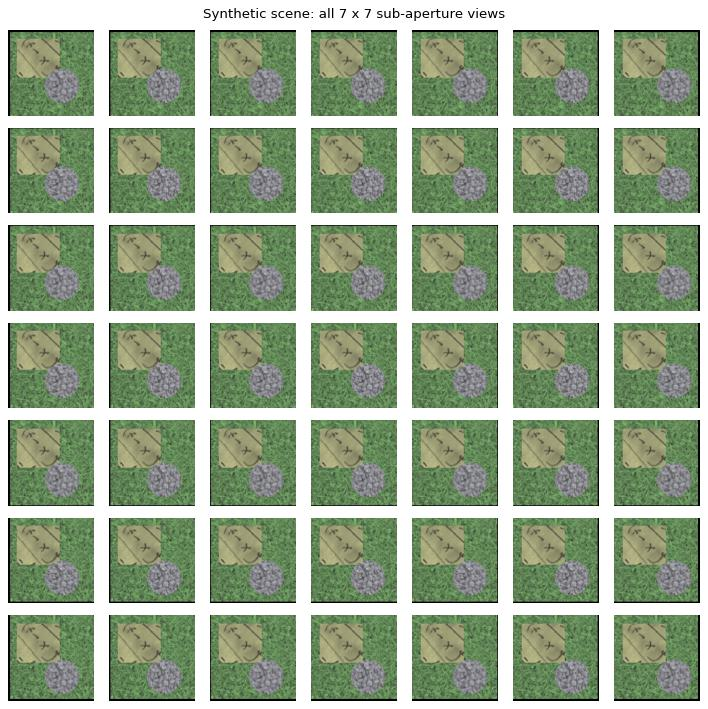

In [2]:
L_syn = synthetic.synthetic_light_field(n_views=7, size=128)
print(L_syn)
print('views shape (U, V, H, W, C):', L_syn.views.shape, '| dtype:', L_syn.views.dtype)
print('layer disparities:', [l['disparity'] for l in L_syn.meta['layers']])
utils.view_grid(L_syn, step=1, figsize=(9, 9), title='Synthetic scene: all 7 x 7 sub-aperture views');

Neighbouring views look almost identical, but the near gravel disc moves much more between views than the far grass does. That relative motion is the parallax that refocusing and depth estimation exploit in the next notebooks.

## Lego Knights, a real gantry capture

The Stanford gantry moved a camera over a plane. We keep the central $9 \times 9$ views and downsample by 4, which keeps the data at about 60 MB. Never lower `downsample` for this dataset: the full-resolution set is 3.6 GB as float32.

LightField('stanford_lego_knights', angular 9x9, spatial 256x256, 3 ch) | memory: 64 MB


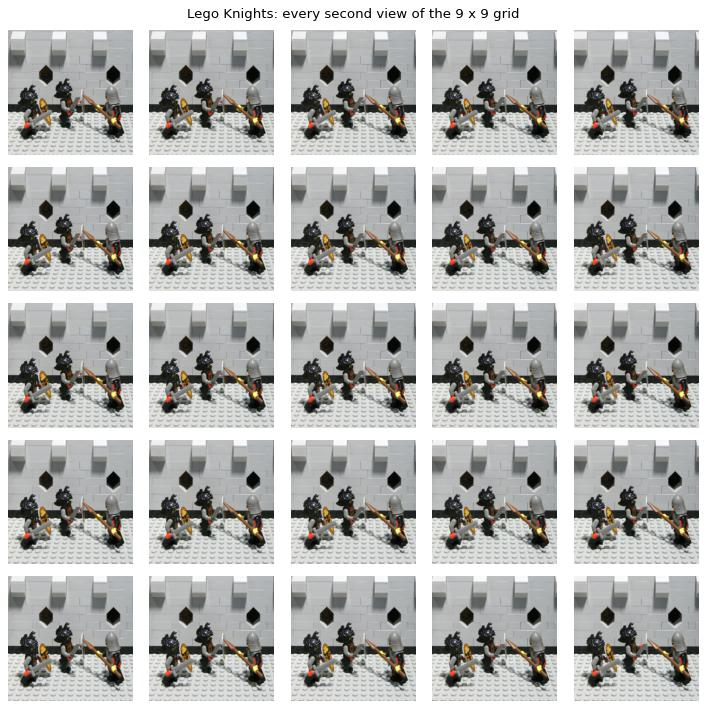

In [3]:
L_lego = lfio.load('lego', downsample=4, angular_crop=9)
print(L_lego, '| memory:', round(L_lego.views.nbytes / 1e6), 'MB')
utils.view_grid(L_lego, step=2, figsize=(9, 9), title='Lego Knights: every second view of the 9 x 9 grid');

## Epipolar-plane images (EPIs)

Fix one image row and one angular row, then stack that image row across all angular columns. The result is an EPI. A scene point with disparity $d$ shifts by $d$ pixels for each step of the viewpoint, so it traces a straight line whose slope is $d$. The right panel is the EPI of row 70, which crosses all three layers of the synthetic scene.

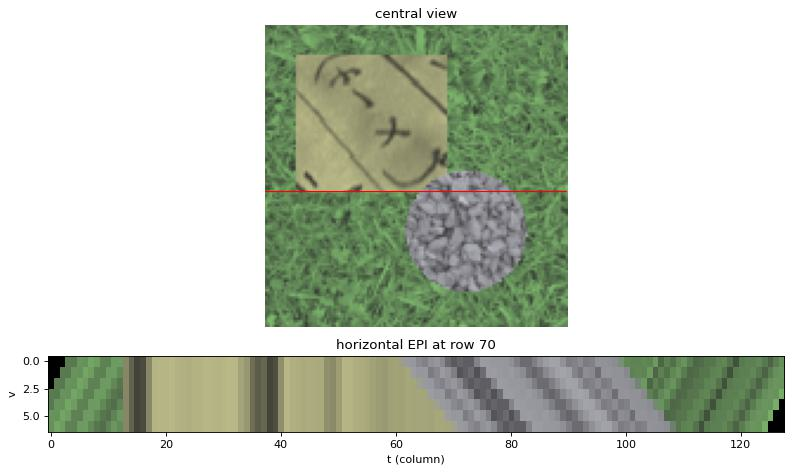

In [4]:
utils.epi_figure(L_syn, row=70, figsize=(10, 6));

Each textured stripe in the EPI is a straight line, and its tilt is the disparity of that layer. The text sits on the focal plane, so its line is vertical; the grass and the gravel tilt in opposite directions, with the nearer gravel tilting more.

## A real micro-lens capture (optional)

If the Lytro Illum ESLF is on disk, decode it into the same `(U, V, H, W, C)` layout. Its 14 x 14 micro-lens tiles were already split into sub-aperture images by `lf.io`. Otherwise this cell only prints a message.

LightField('flowers_plants_1_eslf', angular 9x9, spatial 188x270, 3 ch)


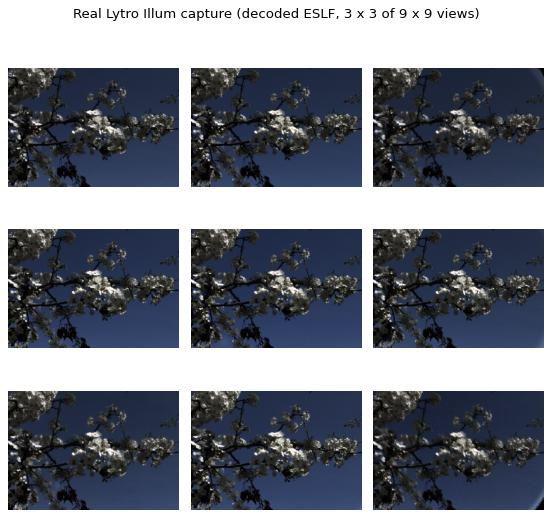

In [5]:
if lfio.available()['lytro']:
    L_real = lfio.load('lytro', downsample=2)
    print(L_real)
    utils.view_grid(L_real, step=4, figsize=(7, 7), title='Real Lytro Illum capture (decoded ESLF, 3 x 3 of 9 x 9 views)')
else:
    print('Lytro dataset not on disk; run scripts/download_data.py lytro to enable this cell.')

## The plenoptic sensor image

A plenoptic camera puts a micro-lens array in front of the sensor, so each micro-lens covers a block of pixels that records the rays arriving from different parts of the lens. `to_lenslet` simulates that raw mosaic and `from_lenslet` inverts it exactly. Here we use the synthetic scene because its raw image is small enough to display.

raw sensor image: (896, 896, 3) | light field: (7, 7, 128, 128, 3)
round trip is exact: True


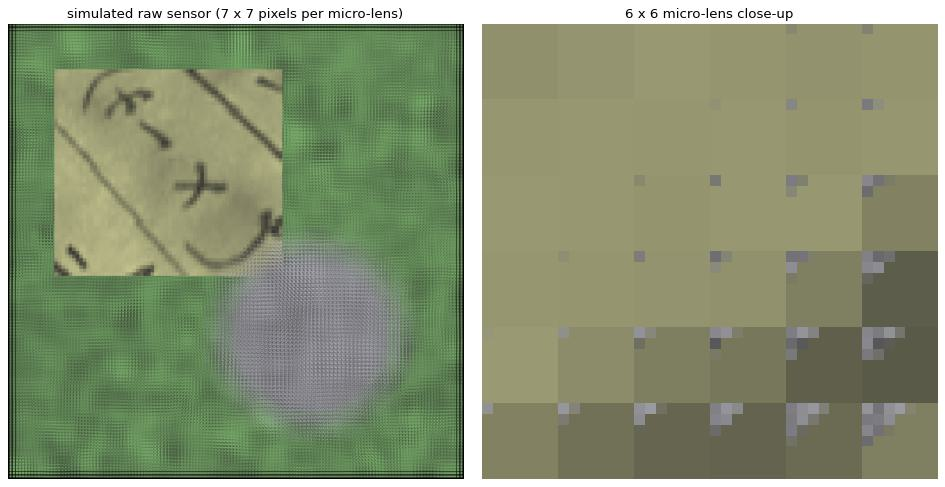

In [6]:
raw = plenoptic.to_lenslet(L_syn)
print('raw sensor image:', raw.shape, '| light field:', L_syn.views.shape)
print('round trip is exact:', np.allclose(plenoptic.from_lenslet(raw, (7, 7)).views, L_syn.views))

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 6))
a.imshow(np.clip(raw, 0, 1))
a.set_title('simulated raw sensor (7 x 7 pixels per micro-lens)'); a.axis('off')
close = plenoptic.lenslet_closeup(raw, (7, 7), center_st=(64, 64), n_lenses=6)
b.imshow(np.clip(close, 0, 1))
b.set_title('6 x 6 micro-lens close-up'); b.axis('off')
plt.tight_layout()

Each tile is one micro-lens, and the pixels inside a tile are the rays that micro-lens received, one pixel per angular position. Resolution is traded for angle: here 7 x 7 angular samples cost a factor 49 in spatial pixels.

## Sub-aperture extraction

Taking the same pixel under every micro-lens gives one sub-aperture image, which is the view through one part of the lens. `from_lenslet` does this for all $(u, v)$ at once.

raw[1::7, 2::7] equals view (1, 2): True


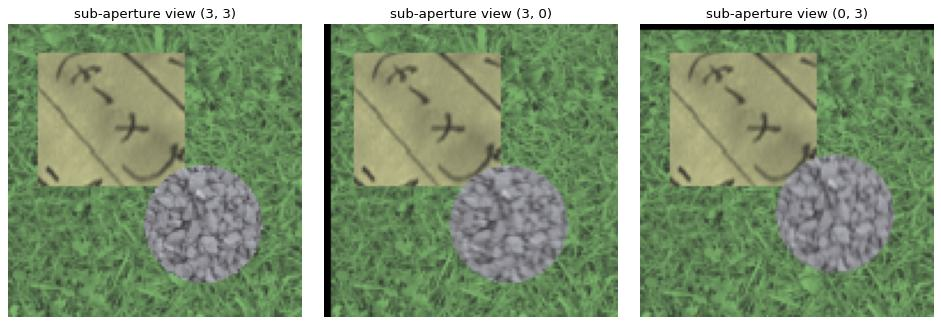

In [7]:
L_dec = plenoptic.from_lenslet(raw, (7, 7))
print('raw[1::7, 2::7] equals view (1, 2):', np.allclose(raw[1::7, 2::7], L_dec.view(1, 2)))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (u, v) in zip(axes, [(3, 3), (3, 0), (0, 3)]):
    ax.imshow(np.clip(L_dec.view(u, v), 0, 1))
    ax.set_title(f'sub-aperture view ({u}, {v})'); ax.axis('off')
plt.tight_layout()

The centre view is the pinhole picture through the middle of the lens, and the edge views see the scene from the side. The shift between them is exactly the parallax from the EPI section.

## One exposure, many photographs

A conventional photo is the average of all pixels under each micro-lens. Averaging only a central disc of the block is the same as a smaller aperture, so one plenoptic capture gives a whole family of stopped-down photos after the fact. The first panel is the full aperture; the others use discs of radius 4, 2, 1 and 0 views.

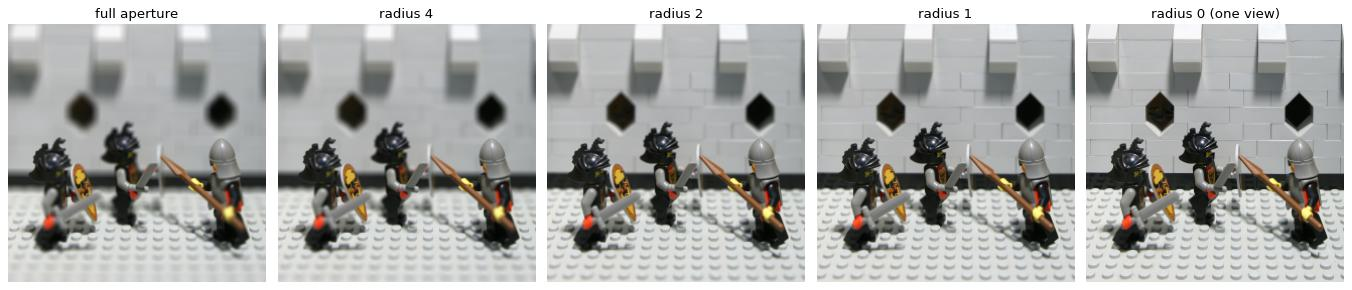

In [8]:
panels = [('full aperture', None), ('radius 4', 4), ('radius 2', 2), ('radius 1', 1), ('radius 0 (one view)', 0)]
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, (title, r) in zip(axes, panels):
    img = plenoptic.conventional_photo(L_lego, radius=r)
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(title); ax.axis('off')
plt.tight_layout()

With the full aperture only the rectification plane is sharp, and the blur grows away from it. Shrinking the disc buys depth of field, until a single view is sharp everywhere. This data is noise-free, so the cost of stopping down (less light, more noise) does not show here.

## Designing a plenoptic camera

`plenoptic.design` turns sensor size, pixel pitch, micro-lens pitch and main-lens f-number into the numbers of Ng et al. (2005). The micro-lens f-number is $f_m / p$, and it should equal the main-lens f-number, otherwise the micro-lens images are the wrong size for their cells.

In [9]:
designs = {f'f/{N}': plenoptic.design(main_f_number=N) for N in (4.0, 2.8)}
keys = ['angular_resolution', 'n_microlenses', 'microlens_f_number', 'f_numbers_match',
        'microlens_image_diameter_px', 'overlap_fraction', 'wasted_fraction', 'total_rays']
print(f"{'quantity':30s}" + ''.join(f'{name:>16s}' for name in designs))
for k in keys:
    cells = []
    for d in designs.values():
        val = d[k]
        cells.append(f'{val:16.3f}' if isinstance(val, float) else f'{str(val):>16s}')
    print(f'{k:30s}' + ''.join(cells))

print()
print(f"{'camera':60s} {'sensor':>12s} {'angular':>9s} {'spatial (slide)':>16s}")
for row in plenoptic.camera_table():
    print(f"{row['camera']:60s} {str(row['sensor_px']):>12s} {str(row['angular']):>9s} {str(row['spatial_slide']):>16s}")

quantity                                 f/4.0           f/2.8
angular_resolution                    (14, 14)        (14, 14)
n_microlenses                       (287, 287)      (287, 287)
microlens_f_number                       4.000           4.000
f_numbers_match                           True           False
microlens_image_diameter_px             13.889          19.841
overlap_fraction                         0.000           0.376
wasted_fraction                          0.215           0.000
total_rays                            16144324        16144324

camera                                                             sensor   angular  spatial (slide)
Ng 2005 prototype (slide labels it Lytro, 16 MP)             (4000, 4000)  (14, 14)       (292, 292)
Sensor 2656x1216                                             (2656, 1216)  (16, 16)        (166, 76)
Sensor 4044x3240                                             (4044, 3240)    (5, 4)       (808, 810)
Sensor 1629x2052            

The f/4 column matches: the micro-lens images just fill their cells, with little overlap. The f/2.8 main lens overfills the micro-lenses, so neighbouring cells overlap and cross-talk rises. The last table is the resolution trade-off from lecture 16.

## Where to go next

Continue with [docs/02_plenoptic_camera.md](../docs/02_plenoptic_camera.md) for the derivations behind this notebook, and read [docs/00_background.md](../docs/00_background.md) and [docs/01_datasets.md](../docs/01_datasets.md) if you want the notation and the data formats. Notebook 02 uses the same light fields to refocus and change the aperture. The matching tab in the Streamlit explorer (`streamlit run app/streamlit_app.py`) lets you play with the same functions.